# Financiación de maquinaria amarilla con un crédito en dólares y cobertura con forwards

**Trabajo final de Derivados · Universidad EAFIT · Octubre de 2026**  
Autores: Alexandros Gallego Rios y equipo *(completar con los integrantes del grupo)*

Este cuaderno es el informe completo: el texto del análisis va junto al código en Python que produce cada cifra, tabla y gráfica. Las tablas numeradas (Tabla 1 a 18) y las figuras corresponden al informe en formato APA; las tablas sin número son salidas directas del código. El código está en dos módulos del repositorio:

| Archivo | Contenido |
|---|---|
| `simulacion_trm.py` | Parte A: tabla de amortización, simulación Monte Carlo de la TRM (20.000 trayectorias, 40 trimestres) y conversión de las cuotas a pesos |
| `cobertura_forward.py` | Parte B: cuatro forwards anuales (NDF) sobre el 75 % de los pagos de los años 7 a 10, con innovaciones normales y t de Student |
| `data/trm_historica_trimestral.csv` | TRM de cierre trimestral, 1993–2026 |
| `documentos/` | Informe en Word (APA) y libro de Excel con la amortización, la conversión a pesos y la cobertura |

**Contenido:** Introducción · A.1 Análisis fundamental · A.2 Crédito en dólares · A.3 Conversión a pesos · B. Cobertura forward (B.1, B.2, B.3) · Referencias

In [1]:
# Configuración: librerías y módulos del proyecto
%matplotlib agg
import contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

import simulacion_trm as sim
import cobertura_forward as cob

pd.set_option("display.max_columns", 30)
print(f"TRM inicial: {sim.S0:,.2f} | trayectorias: {sim.N_SIM:,} | semilla: {sim.SEED}")

TRM inicial: 3,174.67 | trayectorias: 20,000 | semilla: 42


# Introducción

Se plantea la compra de maquinaria amarilla por COP 400 millones. Los inversionistas aportan el 10 % y el 90 % restante (COP 360 millones) se financia con un crédito en Estados Unidos, denominado en dólares, a 10 años y amortizado por sistema francés con cuotas trimestrales constantes. Como los ingresos del proyecto llegan en pesos y las cuotas se pagan en dólares, la empresa queda expuesta a la devaluación del peso.

# A.1. Análisis fundamental de la TRM y expectativa a un año

## Expectativa central

El análisis espera una depreciación moderada del peso en los próximos doce meses: una TRM entre \$3.250 y \$3.500 en octubre de 2027, frente a \$3.174,67 en la fecha de valoración, con un valor esperado cercano a \$3.394, es decir, un alza del dólar de alrededor de 7 %. La expectativa no pretende adivinar un número exacto; busca un rango razonable respaldado por los datos. El punto de partida es un peso muy fuerte: el dólar acumula una caída de 15,61 % en 2026 ([Global66, 2026](https://www.global66.com/blog/dolar-hoy-colombia-analisis-semanal-16-octubre-2026/); [Portafolio, 2026d](https://www.portafolio.co/economia/finanzas/precio-del-dolar-hoy-en-colombia-asi-cotiza-la-divisa-al-cierre-de-la-semana-504976)), impulsada por tres apoyos: el diferencial de tasas de interés, el petróleo caro y una menor prima de riesgo político después de las elecciones. La idea central del análisis es que esos tres apoyos tienden a debilitarse en 2027, mientras el riesgo fiscal aumenta.

## Condiciones iniciales

La TRM vigente entre el 17 y el 19 de octubre de 2026 fue \$3.174,67 por dólar, después de bajar desde \$3.312,84 el 1 de octubre ([Wilkinson PC, s. f.](https://dolar.wilkinsonpc.com.co/)). En los días siguientes el dólar se mantuvo cerca de ese nivel: la TRM del 23 de octubre fue \$3.185,01 ([Portafolio, 2026d](https://www.portafolio.co/economia/finanzas/precio-del-dolar-hoy-en-colombia-asi-cotiza-la-divisa-al-cierre-de-la-semana-504976)), de modo que la fecha de valoración sigue siendo representativa.

Como punto de referencia se calculan dos paridades. No son pronósticos, sino valores teóricos que ayudan a ubicar la expectativa:

**Tabla 1**

*Paridades de referencia para la TRM a 12 meses*

| **Método**                             | **Cálculo**                             | **TRM de referencia a 12 meses** |
|----------------------------------------|-----------------------------------------|----------------------------------|
| Paridad de tasas de interés (cubierta) | 3.174,67 × (1 + 12,25 %) / (1 + 4,51 %) | ≈ \$3.410                        |
| Paridad de poder adquisitivo relativa  | 3.174,67 × (1 + 6,29 %) / (1 + 3,7 %)   | ≈ \$3.254                        |

La paridad de tasas indica cuánto costaría hoy asegurar (cubrir) el precio del dólar a un año: como las tasas en Colombia son mucho más altas que en Estados Unidos, el dólar a futuro es más caro que el dólar de contado. La paridad de poder adquisitivo indica cuánto se depreciaría el peso si solo importara la diferencia de inflación entre los dos países. Ambas apuntan a un dólar más caro que hoy. Sin embargo, en 2026 el peso se apreció en lugar de depreciarse, porque el diferencial de tasas atrajo capital extranjero más conocido como *carry trade*.

## Diferencial de tasas y política monetaria

Ambos bancos centrales están subiendo tasas, pero Colombia parte de un nivel mucho más alto. El diferencial nominal es de unos 8,4 puntos porcentuales y el real, de unos 5,8 puntos. Mientras ese diferencial se mantenga, el *carry trade* sigue siendo atractivo y se sostiene la demanda por la moneda.

**Tabla 2**

*Política monetaria en Colombia y Estados Unidos*

|                         | **Colombia (Banco de la República)**                                                                  | **Estados Unidos (Reserva Federal)**                                           |
|-------------------------|-------------------------------------------------------------------------------------------------------|--------------------------------------------------------------------------------|
| Tasa de política        | 12,25 %                                                                                               | 3,75 %–4,00 %                                                                  |
| Última decisión         | Alza de 25 pb el 30 de septiembre (4 votos por +25 pb, 2 por mantener y 1 por +50 pb)                 | Alza de 25 pb el 16 de septiembre, 12–0; la primera desde 2023                 |
| Inflación anual         | 6,29 % (septiembre)                                                                                   | 3,7 % (septiembre)                                                             |
| Tasa real aproximada    | 12,25 − 6,29 ≈ 6,0 %                                                                                  | 3,875 − 3,7 ≈ 0,2 %                                                            |
| Señal de próximos pasos | Postura restrictiva; atento a El Niño, a la reconstrucción tras el terremoto y a las medidas fiscales | 16 de 18 miembros esperan otra alza en 2026; mediana de 4,1 % para 2026 y 2027 |
| Próxima reunión         | Finales de octubre                                                                                    | 27 y 28 de octubre (comunicado el 28)                                          |

Fuentes: [Portafolio (2026b)](https://www.portafolio.co/economia/finanzas/el-banco-de-la-republica-aumenta-la-tasa-de-interes-en-25-puntos-basicos-y-queda-en-12-503597), [Chase (2026)](https://www.chase.com/personal/investments/learning-and-insights/article/federal-reserve-raises-rates-officials-signal-one-more-hike-in-2026), [Forex Fundamentals (2026)](https://forexfundamentals.com/economic-calendar/us-cpi/2026-10-14), [PrimeRates (2026)](https://primerates.com/prime-rate-rises-7-percent-fed-first-hike-since-july-2023/).

Para el peso, el riesgo está en que el diferencial se reduzca: eso ocurriría si la Fed sube más de lo esperado o si el Banco de la República se detiene. En la reunión de finales de octubre de 2026, el mercado le asigna una probabilidad de 80,5 % a que la Fed mantenga su tasa ([Portafolio, 2026d](https://www.portafolio.co/economia/finanzas/precio-del-dolar-hoy-en-colombia-asi-cotiza-la-divisa-al-cierre-de-la-semana-504976)), mientras que en Colombia cinco de los siete directores votaron por subir en septiembre ([Global66, 2026](https://www.global66.com/blog/dolar-hoy-colombia-analisis-semanal-16-octubre-2026/)), por lo que otra alza local es probable. En el corto plazo, entonces, el diferencial se mantendría. El debilitamiento esperado se concentra en 2027, cuando el Banco de la República debería empezar a bajar tasas si la inflación cede como se espera.

## Inflación esperada

La inflación colombiana sigue subiendo y supera a la estadounidense en 2,59 puntos porcentuales. A largo plazo, una inflación más alta en Colombia presiona al peso hacia abajo, aunque las tasas altas compensan ese efecto mientras se mantenga el aumento. En Colombia, la inflación anual llegó a 6,29 % en septiembre, el dato más alto desde julio de 2024 ([Portafolio, 2026c](https://www.portafolio.co/economia/finanzas/inflacion-en-colombia-sigue-subiendo-se-ubico-en-6-29-en-septiembre-de-504077)), y la inflación básica fue 6,1 % en agosto, la mayor en un año. Los analistas esperan 6,8 % en diciembre de 2026 y solo 4,0 % a dos años, y el Banco de la República afirma que su postura es consistente con una inflación a la baja en 2027 ([Portafolio, 2026b](https://www.portafolio.co/economia/finanzas/el-banco-de-la-republica-aumenta-la-tasa-de-interes-en-25-puntos-basicos-y-queda-en-12-503597)).

En Estados Unidos, la inflación anual subió de 3,4 % en agosto a 3,7 % en septiembre, por encima del 3,6 % que esperaba el mercado ([Forex Fundamentals, 2026, con datos del BLS](https://forexfundamentals.com/economic-calendar/us-cpi/2026-10-14)), parte del alza viene de la energía, encarecida por el conflicto con Irán ([Chase, 2026](https://www.chase.com/personal/investments/learning-and-insights/article/federal-reserve-raises-rates-officials-signal-one-more-hike-in-2026)). Si la inflación colombiana no baja en 2027 como espera el banco central, este factor pasaría a presionar al alza el precio del dólar.

## Petróleo, balanza de pagos y flujos de inversión

El petróleo caro y la inversión extranjera directa respaldan al peso, el déficit externo creciente y las salidas de inversión de portafolio lo limitan. El Brent llegó a US\$131 el 15 de septiembre por ataques a infraestructura petrolera en Arabia Saudita y flujos restringidos desde Medio Oriente, y el 16 de octubre rondaba US\$105. La Administración de Información Energética de EE. UU. (EIA) proyecta un promedio de US\$96,32 en 2026 y de US\$83,74 en 2027, con US\$105 en el cuarto trimestre de 2026 y US\$74 en el cuarto trimestre de 2027 ([Rigzone, 2026, con el informe STEO de octubre](https://www.rigzone.com/news/eia_boosts_oil_price_forecast_by_5_in_2026_10_in_2027-08-oct-2026-184805-article/)). Como el petróleo es el principal producto de exportación de Colombia, la caída prevista en 2027 reduciría la entrada de dólares y le quitaría gran parte del apoyo al peso.

**Tabla 3**

*Balanza de pagos de Colombia, primer semestre de 2026*

| **Balanza de pagos, primer semestre de 2026** | **Dato**                                                      |
|-----------------------------------------------|---------------------------------------------------------------|
| Déficit de cuenta corriente                   | US\$5.981 millones (2,3 % del PIB; 2,0 % un año antes)        |
| Exportaciones de bienes                       | US\$28.344 millones (+13,6 %; oro y petróleo)                 |
| Importaciones de bienes                       | US\$36.155 millones (+14,2 %; bienes de consumo y de capital) |
| Inversión extranjera directa                  | US\$8.138 millones (+31,1 %; 3,1 % del PIB)                   |
| Inversión de portafolio extranjera            | Salidas netas de US\$3.032 millones                           |
| Posición de inversión internacional neta      | −US\$204.240 millones (≈ 40 % del PIB)                        |

Fuente: [Bloomberg Línea (2026), con datos del Banco de la República](https://www.bloomberglinea.com/latinoamerica/colombia/deficit-externo-de-colombia-se-amplia-a-us5981-millones-en-el-primer-semestre-de-2026/).

Bancolombia proyecta un déficit corriente de 2,5 % a 2,8 % del PIB para 2026 y remesas estables cerca de 3,4 % del PIB ([Valora Analitik, 2026](https://es-us.noticias.yahoo.com/d%C3%B3lar-colombia-llegar%C3%ADa-4-000-170000304.html)); Credicorp Capital lo estima en 2,7 % ([Portafolio, 2026a](https://www.portafolio.co/economia/finanzas/dolar-en-colombia-el-alza-esperada-para-el-cierre-de-2026-y-por-que-podria-subir-a-3-600-en-2027-segun-credicorp-505043)). Se puede decir que la inversión directa todavía alcanza a financiar el déficit, pero también se muestra que a corto plazo los inversionistas pueden reaccionar a un cambio en la exposición al riesgo.

## Riesgo país

**Tabla 4**

*Calificación soberana de Colombia*

| **Calificadora** | **Nota** | **Perspectiva** | **Acción más reciente**                                                                                                                                                                                                |
|------------------|----------|-----------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| S&P              | BB−      | Estable         | Rebaja el 8 de abril de 2026 ([El Espectador, 2026](https://www.elespectador.com/economia/sp-rebaja-la-calificacion-de-colombia-a-bb-las-razones-detras-de-la-decision/))                                              |
| Fitch            | BB       | Estable         | Rebaja el 17 de diciembre de 2025 ([XTB, 2025](https://www.xtb.com/lat/analisis-y-noticias/analisis-de-mercado/fitch-rebaja-la-calificacion-de-colombia-a-bb-y-alerta-por-deficits-fiscales-persistentes))             |
| Moody's          | Baa3     | Estable         | Rebaja desde Baa2 en junio de 2025 ([Portafolio, 2025](https://www.portafolio.co/economia/crecimiento/calificacion-crediticia-de-colombia-baja-por-deficit-fiscal-y-deuda-creciente-analisis-de-s-p-y-moody-s-634057)) |

Las tres calificadoras rebajaron a Colombia en el último año y medio, y S&P advierte que podría hacerlo de nuevo en 6 a 18 meses si los déficits superan lo previsto o se debilita la credibilidad del banco central. A favor del peso está que la prima de riesgo político bajó tras las elecciones ([Valora Analitik, 2026](https://es-us.noticias.yahoo.com/d%C3%B3lar-colombia-llegar%C3%ADa-4-000-170000304.html)).

## Condiciones fiscales y políticas

El déficit fiscal es el principal riesgo para el peso. El Comité Autónomo de la Regla Fiscal lo proyecta en 7,2 % del PIB en 2026 y 9,4 % en 2027, y la regla fiscal permanece suspendida hasta 2027 ([Infobae, 2026a](https://www.infobae.com/colombia/2026/10/18/creditos-y-costo-de-vida-se-encarecerian-en-colombia-ante-el-desajuste-de-dinero-que-le-dejo-gustavo-petro-al-pais-es-dispararnos-en-el-pie/)). Un déficit tan alto obliga al Gobierno a endeudarse más, y si los inversionistas dudan de que pueda corregirlo, exigen tasas más altas por los TES o retiran capital, lo que debilita al peso.

En la agenda del Gobierno, el presidente Abelardo De La Espriella insiste en recortar el gasto y busca apoyo del FMI. Según Infobae (2026a), el Congreso aprobó el presupuesto de 2027 por COP 634,9 billones, pendiente de sanción, y se espera la llamada “Ley de Rescate” en la segunda mitad de octubre ([Global66, 2026](https://www.global66.com/blog/dolar-hoy-colombia-analisis-semanal-16-octubre-2026/)). Credicorp Capital pronostica que las presiones fiscales y las operaciones de monetización de divisas del Gobierno son una de las razones por las que espera un dólar más alto en 2027 ([Portafolio, 2026a](https://www.portafolio.co/economia/finanzas/dolar-en-colombia-el-alza-esperada-para-el-cierre-de-2026-y-por-que-podria-subir-a-3-600-en-2027-segun-credicorp-505043)). El Banco de la República, además, vigila tres factores locales: El Niño, la reconstrucción tras el terremoto del 10 de agosto y las medidas fiscales.

## Proyecciones de terceros

Las proyecciones publicadas ubican el dólar entre \$3.150 y \$3.460 al cierre de 2026 y, las que llegan a 2027, entre \$3.428 y \$3.600. En casi todos los casos el valor proyectado supera al nivel actual.

**Tabla 5**

*Proyecciones publicadas de la TRM*

| **Entidad**                          | **Horizonte**              | **TRM proyectada** | **Nota**                                                       |
|--------------------------------------|----------------------------|--------------------|----------------------------------------------------------------|
| Credicorp Capital                    | Cierre 2026 / cierre 2027  | \$3.250 / \$3.600  | El peso estaría sobrevalorado según sus modelos de valor justo |
| LatinFocus (consenso)                | Cierre 2027                | \$3.428            | Citado por Portafolio (2026a)                                  |
| Encuesta del Banco de la República   | Cierre 2027                | \$3.428            | Citado por Portafolio (2026a)                                  |
| BTG Pactual                          | Cierre 2026                | \$3.460            | Espera volatilidad y una corrección alcista suave hacia 2027   |
| Bancolombia                          | Promedio 2026              | \$3.420            | «Tasa justa» cercana a \$3.600                                 |
| Encuesta del Banco de la República   | Promedio de diciembre 2026 | \$3.300            | Subió desde \$3.200 el mes anterior                            |
| BBVA Research                        | Cierre 2026                | \$3.265            | Anticipa una corrección alcista suave hacia 2027               |
| Fedesarrollo y BVC                   | Promedio de diciembre 2026 | \$3.240            | Bajó desde \$3.300                                             |
| Bank of America y Banco de Occidente | Cierre 2026                | ≈ \$3.150          | Las más favorables para el peso                                |

*Nota.* Fuentes: [Portafolio (2026a)](https://www.portafolio.co/economia/finanzas/dolar-en-colombia-el-alza-esperada-para-el-cierre-de-2026-y-por-que-podria-subir-a-3-600-en-2027-segun-credicorp-505043), [Valora Analitik (2026)](https://es-us.noticias.yahoo.com/d%C3%B3lar-colombia-llegar%C3%ADa-4-000-170000304.html) y [Diario del Huila (2026)](https://diariodelhuila.com/proyeccion-dolar-colombia-2026/).

## Escenarios a doce meses

Con base en lo anterior se construyen tres escenarios.

**Tabla 6**

*Escenarios de la TRM a doce meses*

| **Escenario**                          | **Probabilidad** | **TRM en oct. 2027** | **Qué tendría que pasar**                                                                                                                                                                    |
|----------------------------------------|------------------|----------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Base: el peso se debilita gradualmente | 50 %             | \$3.250–\$3.500      | El Banco de la República se detiene y la Fed sube una vez más, de modo que el diferencial se estrecha, el Brent baja hacia US\$84 de promedio en 2027 (EIA), el déficit sube a 9,4 % del PIB |
| Peso fuerte                            | 25 %             | \$3.000–\$3.250      | La Ley de Rescate y el apoyo del FMI dan credibilidad, el Brent se mantiene sobre US\$95, la inversión directa sigue creciendo y la Fed se detiene                                           |
| Peso débil                             | 25 %             | \$3.500–\$3.900      | Nueva rebaja de S&P o fallas en el ajuste fiscal, salidas de portafolio, Brent por debajo de US\$75, más alzas de la Fed y dólar global fuerte                                               |

Ponderando los puntos medios de cada rango por sus probabilidades, el valor esperado es de más o menos \$3.394, un 6,9 % por encima de la TRM actual. Ese resultado queda entre la paridad de poder adquisitivo (\$3.254) y la paridad de tasas (\$3.410), cerca del consenso de LatinFocus y de la encuesta del Banco de la República para el cierre de 2027 (\$3.428), y por debajo de la proyección de Credicorp (\$3.600) y de la «tasa justa» de Bancolombia (\$3.600).

## Conclusión y riesgos de la expectativa

El peso debería debilitarse moderadamente en los próximos doce meses, porque los tres apoyos que tuvo para revaluarse en 2026 (tasas altas, petróleo caro y menor prima de riesgo político) son los que más probablemente se desgasten, mientras que el riesgo fiscal crece. La dirección del movimiento es clara pero su magnitud es bastante incierta, por lo que se da el rango central de \$3.250 a \$3.500. hay datos que podrían cambiar la expectativa: las decisiones del Banco de la República y de la Fed de finales de octubre, la aprobación y el contenido de la Ley de Rescate y la sanción del presupuesto de 2027, donde un ajuste creíble favorecería el escenario de peso fuerte, el precio del Brent que por debajo de US\$75 empujaría hacia el escenario de peso débil, la perspectiva de las calificadoras y los flujos de portafolio en los próximos datos de balanza de pagos, y la inflación del cuarto trimestre.

# A.2. Simulación del crédito en dólares

## Crédito y tasa seleccionados

Se selecciona un préstamo SBA 7(a) para compra de equipo ofrecido por U.S. Bank, con tasa fija de 13,00 % nominal anual: el Prime Rate de 7,00 % más el margen máximo de 6,0 puntos que la Small Business Administration (SBA) permite para préstamos entre USD 50.001 y 250.000 ([U.S. Small Business Administration, s. f.](https://www.sba.gov/es/node/8664); [NerdWallet, s. f.-d](https://www.nerdwallet.com/article/small-business/sba-loan-rates)). El Prime subió a 7,00 % el 17 de septiembre de 2026, tras el alza de la Fed ([PrimeRates, 2026](https://primerates.com/prime-rate-rises-7-percent-fed-first-hike-since-july-2023/)), y U.S. Bank lo confirmó para su propia tasa preferencial en un comunicado del 16 de septiembre ([U.S. Bank, 2026b](https://s203.q4cdn.com/711684571/files/doc_news/U-S--Bank-Increases-Prime-Lending-Rate-to-7-00-Percent-2026.pdf)). Se usa el tope de la SBA como supuesto conservador, pues refleja el costo para una empresa sin historial crediticio en Estados Unidos, un préstamo real podría pactarse por debajo.

**Tabla 7**

*Condiciones del crédito SBA 7(a) seleccionado*

| **Concepto**                   | **Valor**                                                                                            |
|--------------------------------|------------------------------------------------------------------------------------------------------|
| Monto a financiar              | COP 360.000.000 = USD 113.397,61 (TRM 3.174,67)                                                      |
| Plazo y cuotas                 | 10 años, 40 cuotas trimestrales constantes (sistema francés)                                         |
| Tasa                           | 13,00 % nominal anual fija, trimestre vencido (3,25 % trimestral); 13,65 % efectiva anual            |
| Cuota trimestral               | USD 5.106,06                                                                                         |
| Total pagado / intereses       | USD 204.242,44 / USD 90.844,82                                                                       |
| Comisión de garantía SBA       | 2 % del 85 % garantizado = USD 1.927,76 (COP 6,12 millones); costo efectivo con comisión: 14,13 % EA |
| Forma de cotización y consulta | Prime + margen, fijado al aprobar; fuentes consultadas el 27 de octubre de 2026                      |

La tasa es adecuada para financiar maquinaria por tres razones. Primero, el Prime es la tasa base que los bancos estadounidenses usan para sus préstamos empresariales y la SBA lo toma como referencia para sus topes. Segundo, el programa 7(a) es el más usado en Estados Unidos para financiar los activos productivos de pequeñas empresas, incluye la compra de equipo entre sus usos y permite plazos de hasta 10 años para equipo. Tercero, la modalidad de tasa fija hace que la cuota en dólares sea realmente constante.

## Por qué SBA 7(a) y no SBA 504

Otra opción para realizar el ejercicio sería el programa SBA 504. Su estructura suele ser 50 % de un banco, 40 % de una Certified Development Company (CDC) con garantía de la SBA y 10 % del dueño ([NerdWallet, s. f.-a](https://www.nerdwallet.com/business/loans/learn/sba-504-loans)), el tramo de la CDC tiene una tasa fija baja: 6,60 % efectiva a 10 años en la venta de septiembre de 2026 ([Crowdfunded Wealth, 2026, con datos de SomerCor](https://www.crowdfundedwealth.com/articles/sba-504-loan-rates-2026)), por lo que el 504 sería probablemente más barato.

Aun así, el 7(a) se ajusta mejor al caso. El proyecto, de unos USD 126.000, está muy por debajo del rango en que los CDC consideran viable un 504, que son proyectos de USD 350.000 o más ([University of Wisconsin–Stevens Point, 2026](https://www.uwsp.edu/continuing-education-and-outreach/wp-content/uploads/sites/68/2026/05/7-504-Loan-Program-Slides.pdf)). El 504 son en realidad dos créditos con tasas y plazos distintos, lo que dificulta modelar una única cuota constante por sistema francés. Por último, la tasa del tramo bancario no es pública, así que el costo total no se puede verificar. El 7(a) entrega en un solo crédito el plazo, la periodicidad y una tasa verificable.

## Por qué U.S. Bank

Entre los prestamistas SBA más activos del año fiscal 2026 ([NerdWallet, s. f.-c](https://www.nerdwallet.com/business/loans/learn/sba-lenders)), U.S. Bank es el único que: ofrece el 7(a) para equipo hasta 10 años con opción de tasa fija, no cobra cargos propios de procesamiento, acepta negocios con seis meses de operación ([U.S. Bank, s. f.](https://www.usbank.com/business-banking/business-lending/sba-loans.html)), su préstamo promedio (USD 269.357) se asemeja al del caso. Además, fue el cuarto prestamista 7(a) del país en el año fiscal 2026, con un récord de USD 943 millones ([U.S. Bank, 2026a](https://www.usbank.com/about-us-bank/news-and-stories/article-library/us-bank-boosts-sba-lending-to-a-record-943-million-in-7a-loans.html)).

### Tabla de amortización en Python
Sistema francés con cuotas trimestrales constantes en dólares (los mismos valores de la hoja «Amortización» del Excel).

In [2]:
monto_usd, cuota, amort = sim.tabla_credito()
print(f"Monto financiado: USD {sim._num(monto_usd)}  |  Cuota trimestral: USD {sim._num(cuota)}")
print(f"Total pagado: USD {sim._num(cuota * sim.N_Q)}  |  Intereses: USD {sim._num(amort.interes_usd.sum())}")

tabla_amort = amort.copy()
tabla_amort.insert(1, "año", (tabla_amort.trimestre - 1) // 4 + 1)
tabla_amort.insert(2, "cuota_usd", cuota)
tabla_amort.round(2)

Monto financiado: USD 113.397,61  |  Cuota trimestral: USD 5.106,06
Total pagado: USD 204.242,44  |  Intereses: USD 90.844,82


,trimestre,año,cuota_usd,interes_usd,capital_usd,saldo_usd
0,1,1,5106.06,3685.42,1420.64,111976.97
1,2,1,5106.06,3639.25,1466.81,110510.17
2,3,1,5106.06,3591.58,1514.48,108995.68
3,4,1,5106.06,3542.36,1563.70,107431.98
4,5,2,5106.06,3491.54,1614.52,105817.46
5,6,2,5106.06,3439.07,1666.99,104150.47
6,7,2,5106.06,3384.89,1721.17,102429.30
7,8,2,5106.06,3328.95,1777.11,100652.19
8,9,3,5106.06,3271.20,1834.86,98817.32
9,10,3,5106.06,3211.56,1894.50,96922.83


# A.3. Conversión del crédito a pesos colombianos

Cada cuota en dólares se multiplica por la TRM esperada para su trimestre. Primero se usa la TRM spot de la fecha de valoración (\$3.174,67) como escenario base y después trayectorias trimestrales obtenidas de una simulación Monte Carlo de 20.000 caminos posibles de la TRM. La simulación tiene dos tramos. En el primer año, cada camino se asigna a uno de los tres escenarios de la sección A.1 según su probabilidad (50 %, 25 % y 25 %) y termina en un valor dentro del rango de ese escenario. Del segundo al décimo año, la TRM sigue un paseo aleatorio geométrico.

La deriva y la volatilidad se estiman con la historia de la TRM: se toman los valores de cierre de cada trimestre desde 1993 ([Superintendencia Financiera de Colombia, s. f.,](https://www.superfinanciera.gov.co/publicaciones/9332/informes-y-cifrascifrasestablecimientos-de-creditoinformacion-periodicamensualtasas-de-referencia-mensualhistorico-trm-para-estados-financieros-9332/) hasta 2022; [Federal Reserve Bank of St. Louis, s. f.-b,](https://fred.stlouisfed.org/series/COLCCUSSP02STQ) para 2023; cierres de mercado de [Pound Sterling Live \[s. f.-a, s. f.-b\]](https://www.poundsterlinglive.com/history/USD-COP-2024) y [ValutaFX \[s. f.\]](https://www.valutafx.com/history/cop-usd-2026) para 2024 a septiembre de 2026), se calculan los rendimientos logarítmicos trimestrales y la deriva se obtiene como su promedio y la volatilidad como su desviación estándar, ambas anualizadas. Como no hay una respuesta única sobre cuánta historia usar, se probaron seis ventanas:

**Tabla 8**

*Parámetros de la TRM según la ventana histórica*

| **Ventana**                 | **Trimestres** | **Deriva anual** | **Volatilidad anual** | **TRM mediana año 10** | **Costo medio (COP mill.)** |
|-----------------------------|----------------|------------------|-----------------------|------------------------|-----------------------------|
| 3 años (2023–2026)          | 12             | −6,4 %           | 8,5 %                 | 1.906                  | 545,5                       |
| 5 años (2021–2026)          | 20             | −2,6 %           | 11,4 %                | 2.680                  | 638,3                       |
| 10 años (2016–2026)         | 40             | 1,5 %            | 13,2 %                | 3.877                  | 765,0                       |
| 20 años (2006–2026)         | 80             | 1,7 %            | 13,9 %                | 3.938                  | 774,4                       |
| Flotación libre (1999–2026) | 108            | 1,9 %            | 13,1 %                | 4.017                  | 778,3                       |
| Serie completa (1993–2026)  | 134            | 4,4 %            | 12,9 %                | 5.031                  | 869,3                       |

Las ventanas de tiempo cortas reflejan mejor el momento actual (tasas altas y menor prima de riesgo), pero tienen muy pocos datos y capturan una racha de apreciación del peso que, proyectada a diez años, lleva el dólar a más o menos \$1.900, un resultado poco creíble y contrario al análisis fundamental anteriormente hecho. La serie completa tiene el menor error, pero incluye la banda cambiaria y la inflación de 20 %–30 % de los años noventa, que inflan la deriva a 4,4 % y ya no representan la economía actual. Las ventanas de 10, 20 y 27 años dan resultados muy parecidos entre sí.

Por eso se elige la ventana de flotación libre (octubre de 1999 a septiembre de 2026): es la más larga dentro del mismo régimen cambiario (tasa de cambio flexible y metas de inflación), su deriva de 1,9 % anual es cercana al diferencial de inflación esperado a largo plazo entre los dos países y su volatilidad de 13,1 % coincide con la de las ventanas de 10 y 20 años, lo que sugiere que este parámetro es estable.

### Simulación de la TRM (parte A)
La celda corre `simulacion_trm.main()`: estima la deriva y la volatilidad para las seis ventanas históricas, simula 20.000 trayectorias y guarda tablas y gráficas en `resultados/`.

In [3]:
sim.MOSTRAR_TABLAS = False          # las tablas de 40 trimestres se muestran más abajo
with contextlib.redirect_stdout(io.StringIO()):
    resA = sim.main()

ventanas = resA["ventanas"][["ventana", "n_trimestres", "deriva_anual", "volatilidad_anual",
                             "error_est_deriva", "TRM_p50_anio10", "costo_total_cop_media"]].copy()
ventanas["costo_total_cop_media"] /= 1e6
ventanas.columns = ["Ventana", "Trimestres", "Deriva anual", "Volatilidad anual",
                    "Error est. deriva", "TRM mediana año 10", "Costo medio (COP mill.)"]
ventanas.style.format({"Deriva anual": "{:.1%}", "Volatilidad anual": "{:.1%}", "Error est. deriva": "{:.1%}",
                       "TRM mediana año 10": "{:,.0f}", "Costo medio (COP mill.)": "{:,.1f}"}).hide(axis="index")

Ventana,Trimestres,Deriva anual,Volatilidad anual,Error est. deriva,TRM mediana año 10,Costo medio (COP mill.)
3 años (2023-2026),12,-6.4%,8.5%,4.9%,"1,906",545.5
5 años (2021-2026),20,-2.6%,11.4%,5.1%,"2,680",638.3
10 años (2016-2026),40,1.5%,13.2%,4.2%,"3,877",765.0
20 años (2006-2026),80,1.7%,13.9%,3.1%,"3,938",774.4
Flotación libre (1999-2026),108,1.9%,13.1%,2.5%,"4,017",778.3
Serie completa (1993-2026),134,4.4%,12.9%,2.2%,"5,031",869.3


In [4]:
total = resA["total"]
tir = cob.tir_ea(sim.VALOR_MAQUINARIA_COP * (1 - sim.APORTE), cuota * resA["paths"][:, 1:])   # TIR de las 20.000 trayectorias
spot_total = cuota * sim.N_Q * sim.S0
resumen_A = pd.DataFrame({
    "Indicador": ["Total pagado en COP (millones)", "Diferencia frente a TRM spot (millones)",
                  "Costo efectivo anual en COP"],
    "Media": [total.mean() / 1e6, (total.mean() - spot_total) / 1e6, tir.mean()],
    "P5": [np.percentile(total, 5) / 1e6, (np.percentile(total, 5) - spot_total) / 1e6, np.percentile(tir, 5)],
    "P50": [np.percentile(total, 50) / 1e6, (np.percentile(total, 50) - spot_total) / 1e6, np.percentile(tir, 50)],
    "P95": [np.percentile(total, 95) / 1e6, (np.percentile(total, 95) - spot_total) / 1e6, np.percentile(tir, 95)],
})
print(f"Probabilidad de pagar más que con la TRM spot: {(total > spot_total).mean():.1%}")
resumen_A.round(4)

Probabilidad de pagar más que con la TRM spot: 74.8%


,Indicador,Media,P5,P50,P95
0,Total pagado en COP (millones),778.2705,529.1619,752.1311,1115.9474
1,Diferencia frente a TRM spot (millones),129.8682,-119.2405,103.7287,467.5451
2,Costo efectivo anual en COP,0.1739,0.0909,0.1720,0.2627


**Figura 1**

*Trayectorias de la TRM y cuota trimestral del crédito en pesos*

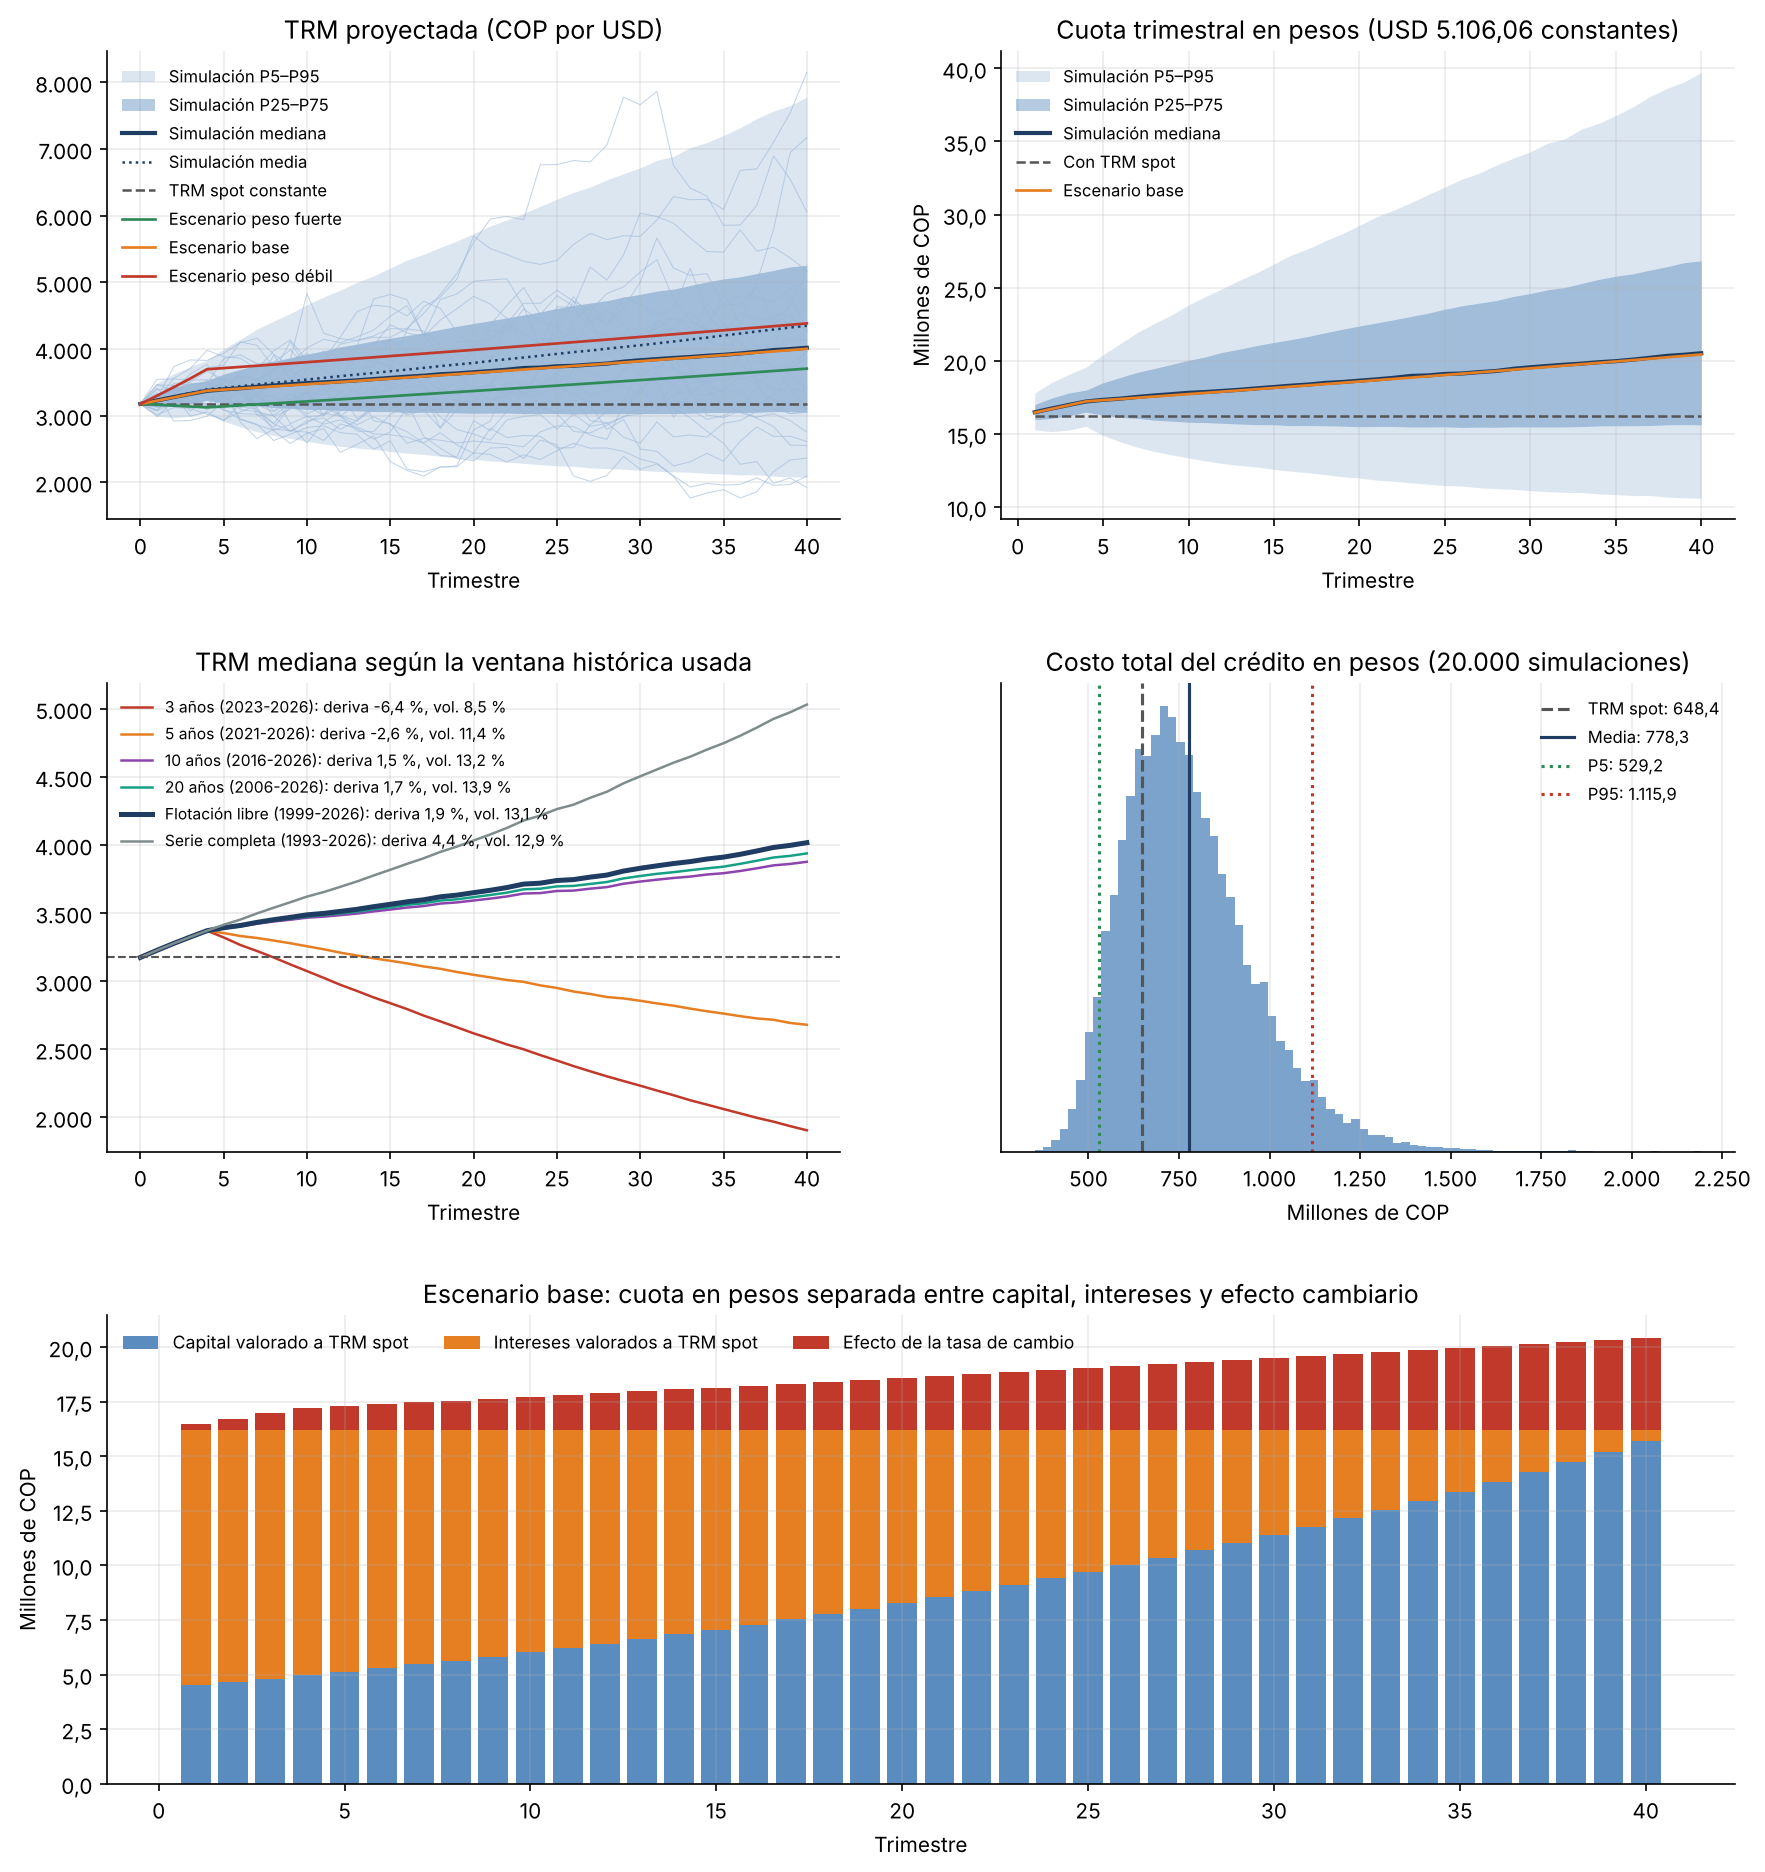

In [5]:
# Figura 1 (generada por simulacion_trm.graficas y guardada en resultados/)
display(Image("resultados/graficas_simulacion_trm.png"))

*Nota.* Las bandas corresponden a percentiles de 20.000 simulaciones. Fuente: elaboración propia con simulacion_trm.py.

## Resultados con las trayectorias proyectadas

**Tabla 9**

*Costo del crédito en pesos según la trayectoria de la TRM*

| **Trayectoria de la TRM**       | **Total, pagado (COP millones)** | **Diferencia vs. spot** | **Costo efectivo anual en COP** |
|---------------------------------|----------------------------------|-------------------------|---------------------------------|
| TRM spot constante              | 648,4                            | —                       | 13,7 %                          |
| Escenario base (camino mediano) | 745,0                            | +14,9 %                 | 16,9 %                          |
| Escenario peso fuerte           | 691,6                            | +6,7 %                  | 14,9 %                          |
| Escenario peso débil            | 813,7                            | +25,5 %                 | 19,5 %                          |

En los tres escenarios de la sección A.1 el crédito cuesta más en pesos que con la TRM spot, incluso en el de peso fuerte, porque después del primer año la TRM retoma una depreciación de largo plazo. En el escenario base la cuota sube de COP 16,46 millones en el primer trimestre a COP 20,43 millones en el último y el costo efectivo en pesos pasa de 13,65 % a 16,9 % anual. La simulación muestra la dispersión del resultado: en 74,8 % de los caminos se paga más que con la TRM spot, en 30 % el costo efectivo supera 20 % anual y en el 5 % de los casos más desfavorables el total pagado llega a más de COP 1.100 millones, más del triple del monto recibido. En el otro extremo, si el peso se apreciara de forma sostenida, el costo podría bajar a cerca de 9 % anual.

## Intereses frente a tasa de cambio

Para separar las dos fuentes de costo, cada cuota se divide en interés y abono a capital (en dólares) y cada parte se valora de dos formas: a la TRM spot y a la TRM proyectada. La diferencia entre ambas es el efecto cambiario.

**Tabla 10**

*Descomposición del costo en intereses y efecto cambiario*

| **Componente (COP millones)**    | **Spot** | **Base** | **Peso fuerte** | **Peso débil** | **Simulación (media)** |
|----------------------------------|----------|----------|-----------------|----------------|------------------------|
| Capital a TRM spot               | 360,0    | 360,0    | 360,0           | 360,0          | 360,0                  |
| Intereses a TRM spot             | 288,4    | 288,4    | 288,4           | 288,4          | 288,4                  |
| Efecto cambiario sobre intereses | 0,0      | 34,5     | 11,8            | 63,6           | 45,1                   |
| Efecto cambiario sobre capital   | 0,0      | 62,1     | 31,3            | 101,7          | 84,7                   |
| Total                            | 648,4    | 745,0    | 691,6           | 813,7          | 778,3                  |

Los intereses del crédito son el costo de financiarse y equivalen a COP 288,4 millones valorados a la TRM spot, un 44 % del total del escenario spot. El efecto cambiario es el costo adicional por endeudarse en otra moneda: COP 96,6 millones en el escenario base y COP 129,9 millones en promedio en la simulación. el interés representa el 72 % de la primera cuota y solo el 3 % de la última. Como la cuota en dólares es constante, toda la variación de la cuota en pesos de un trimestre a otro proviene de la tasa de cambio.

## Efecto sobre el flujo de caja

**Tabla 11**

*Pago anual del crédito en pesos por escenario*

| **Pago anual del crédito (COP millones)** | **Año 1** | **Año 3** | **Año 5** | **Año 10** |
|-------------------------------------------|-----------|-----------|-----------|------------|
| TRM spot                                  | 64,8      | 64,8      | 64,8      | 64,8       |
| Escenario base                            | 67,3      | 71,0      | 73,8      | 81,1       |
| Escenario peso fuerte                     | 64,2      | 65,8      | 68,3      | 75,1       |
| Escenario peso débil                      | 71,4      | 77,8      | 80,8      | 88,9       |

En dólares, la empresa paga lo mismo cada año: USD 20.424. En pesos, el precio crece con la TRM. En el escenario base el pago anual pasa de COP 67,3 millones en el primer año a COP 81,1 millones en el décimo, unos COP 16 millones más que con la TRM spot, y en el escenario de riesgo alto llega a COP 88,9 millones. Si los ingresos de la maquinaria crecen al mismo ritmo de la inflación colombiana, se compensaría parte del aumento, pero una devaluación brusca elevaría la cuota en pocos trimestres sin posibilidad de que los ingresos se ajusten al mismo paso. Estas devaluaciones rápidas ya han pasado anteriormente, como en 2022 y 2015.

## Obligación estable en dólares frente a obligación variable en pesos

Desde el punto de vista de un prestamista estadounidense, el crédito es una obligación estable, con tasa fija, 40 cuotas iguales y un costo de 13,65 % anual conocido desde el primer día. Desde el punto de vista de la empresa colombiana, esa misma obligación se vuelve variable y creciente en pesos, con un costo efectivo que en la simulación va de 9 % a 26 % anual. La diferencia entre las dos miradas es el riesgo cambiario, y crece con el plazo: la banda de resultados posibles se abre cada año, por lo que las cuotas de los años finales son las más inciertas. Comparado con un crédito en pesos, el crédito en dólares solo es conveniente si la tasa local para un crédito con plazo similar supera el costo esperado en pesos del crédito en dólares o si la empresa cubre el riesgo, por ejemplo con contratos forward.

## Conclusiones de la conversión de crédito a pesos colombianos

El crédito cuesta 13,65 % anual en dólares, pero su costo esperado en pesos sube a alrededor de 17 % anual, porque el análisis fundamental y la historia de la TRM apuntan a una depreciación gradual del peso. La mayor parte del sobrecosto proviene de la tasa de cambio aplicada al capital al final del plazo, y no de los intereses.

### Cuota de cada trimestre en pesos
Cuota constante en USD multiplicada por la TRM de cada trayectoria (millones de COP).

In [6]:
tr = resA["trayectorias"]
S = resA["paths"][:, 1:]
cuotas_cop = pd.DataFrame({
    "Trimestre": tr.trimestre[1:].values, "Fecha": tr.fecha[1:].values,
    "Interés USD": amort.interes_usd.values, "Capital USD": amort.capital_usd.values,
    "TRM base": tr.escenario_base[1:].values,
    "Spot": cuota * sim.S0 / 1e6,
    "Base": cuota * tr.escenario_base[1:].values / 1e6,
    "Peso fuerte": cuota * tr.escenario_peso_fuerte[1:].values / 1e6,
    "Peso débil": cuota * tr.escenario_peso_debil[1:].values / 1e6,
    "Sim. media": cuota * S.mean(axis=0) / 1e6,
    "Sim. P5": cuota * np.percentile(S, 5, axis=0) / 1e6,
    "Sim. P95": cuota * np.percentile(S, 95, axis=0) / 1e6,
})
cuotas_cop.round(2)

,Trimestre,Fecha,Interés USD,Capital USD,TRM base,Spot,Base,Peso fuerte,Peso débil,Sim. media,Sim. P5,Sim. P95
0,1,2027-01-18,3685.42,1420.64,3223.06,16.21,16.46,16.14,16.84,16.50,15.27,17.78
1,2,2027-04-18,3639.25,1466.81,3272.18,16.21,16.71,16.08,17.49,16.77,15.15,18.53
2,3,2027-07-18,3591.58,1514.48,3322.05,16.21,16.96,16.01,18.16,17.05,15.26,19.07
3,4,2027-10-18,3542.36,1563.70,3372.68,16.21,17.22,15.94,18.86,17.32,15.52,19.56
4,5,2028-01-18,3491.54,1614.52,3388.72,16.21,17.30,16.02,18.95,17.44,14.89,20.42
5,6,2028-04-18,3439.07,1666.99,3404.84,16.21,17.39,16.10,19.04,17.56,14.45,21.17
6,7,2028-07-18,3384.89,1721.17,3421.03,16.21,17.47,16.17,19.14,17.71,14.08,21.93
7,8,2028-10-18,3328.95,1777.11,3437.29,16.21,17.55,16.25,19.23,17.82,13.79,22.56
8,9,2029-01-18,3271.20,1834.86,3453.64,16.21,17.63,16.33,19.32,17.95,13.56,23.13
9,10,2029-04-18,3211.56,1894.50,3470.06,16.21,17.72,16.40,19.41,18.08,13.34,23.82


# B. Diseño y evaluación de la cobertura forward

Para reducir la exposición al riesgo, se plantea que, una vez terminado el sexto año del crédito, la empresa cubra el 75 % de los pagos en dólares que aún le faltan por pagar con cuatro forwards consecutivos de un año, y deje el 25 % restante expuesto a la tasa spot.

Al cierre del año 6 (trimestre 24) quedan 16 cuotas de USD 5.106,06, una exposición de USD 81.696,97. El 75 % equivale a USD 61.272,73. Como las cuotas anuales son iguales, ese valor se reparte en cuatro forwards de USD 15.318,18.

**Tabla 12**

*Estructura de los forwards de cobertura*

|   **Forward** |   **Año** | **trimestres**   | **Pagos del año (USD)**   | **Cobertura (USD)**   | **Pago pendiente (USD)**   | **Saldo de capital al pactar (USD)**   |
|--------------:|----------:|:-----------------|:--------------------------|:----------------------|:---------------------------|:---------------------------------------|
|             1 |         7 | 24 → 28          | 20.424,24                 | 15.318,18             | 81.696,97                  | 62.928,92                              |
|             2 |         8 | 28 → 32          | 20.424,24                 | 15.318,18             | 61.272,73                  | 50.075,53                              |
|             3 |         9 | 32 → 36          | 20.424,24                 | 15.318,18             | 40.848,49                  | 35.467,96                              |
|             4 |        10 | 36 → 40          | 20.424,24                 | 15.318,18             | 20.424,24                  | 18.866,81                              |

La tabla confirma la coherencia entre el nominal y la obligación: cada forward cubre menos que los pagos de su año, el total cubierto (USD 61.273) es menor que la obligación pendiente (USD 81.697) y también que el saldo de capital al iniciar la cobertura (USD 62.929). Por lo tanto, la estrategia no crea una posición especulativa. Esa coherencia depende de dos condiciones: que el crédito no se prepague, porque los forwards pendientes quedarían sin obligación detrás, y que la tasa del crédito sea fija, como se eligió en A.2. Con una tasa variable las cuotas cambiarían y el nominal tendría que ajustarse.

## B.1. Cotización y valoración de los forwards

Se usó la curva forward USD/COP que publica [Cbonds (s. f.-b)](https://cbonds.com/indexes/215895/), con precios medios al cierre de Londres, que sirven de referencia para valorar forwards con y sin entrega ([detalle por plazos en Cbonds, s. f.-a](https://cbonds.com.tr/indexes/215883/)). Los datos son del 27 de octubre de 2026. El spot de la curva es 3.132,07.

**Tabla 13**

*Curva forward USD/COP al 27 de octubre de 2026*

| **Plazo**  | **Precio (COP por USD)** | **Puntos forward (COP)** | **Devaluación implícita del plazo** |
|------------|--------------------------|--------------------------|-------------------------------------|
| Spot (S/N) | 3.132,07                 |                          |                                     |
| 1 año      | 3.386,30                 | 254,23                   | 8,12 %                              |

Los puntos forward a un año son 254 pesos lo que significa que comprar dólares a un año cuesta 8,12 % más que comprarlos hoy. Para valorar si ese precio es razonable, se calcula el forward teórico con la paridad cubierta de tasas de interés, F = S × (1 + i_COP) / (1 + i_USD). La lógica de hacer esto es ver un posible arbitraje, donde, pedir prestados pesos, comprar dólares hoy e invertirlos en EE. UU. por un año tenga un resultado distinto a invertir directamente en el forward. Como en la paridad deben usarse tasas del mismo plazo, se probaron varias combinaciones:

**Tabla 14**

*Forward teórico según la paridad cubierta de tasas*

| **Combinación de tasas**                             | **i_COP** | **i_USD** | **Forward teórico** | **Diferencia con el observado (3.386,30)** |
|------------------------------------------------------|-----------|-----------|---------------------|--------------------------------------------|
| Tasa de política BanRep vs Tesoro de EE. UU. a 1 año | 12,25 %   | 4,47 %    | 3.365,32            | +20,98 (+0,62 %)                           |

*Nota.* Fuentes de las tasas: [Banco de la República (s. f.)](https://totoro.banrep.gov.co/estadisticas-economicas/), [Board of Governors of the Federal Reserve System (2026)](https://www.federalreserve.gov/releases/h15/),

El forward observado está 21 pesos (0,62 %) por encima del teórico. Despejando la fórmula, el forward de mercado implica una tasa en pesos a un año de 12,95 %, unos 70 puntos básicos por encima de la tasa de política. Esta diferencia puede venir de las siguientes razones:

- **Desalineación entre las tasas utilizadas.** La tasa de política es a un día, mientras que el forward es a un año. El mercado espera que el Banco de la República suba la tasa a 12,50 %. El forward observado queda justo entre la referencia de la tasa de política y la del TES, lo que sugiere que la mayor parte de la brecha se explica por la tasa elegida y no por un error de precio.

- **Spread de negociación.** Cbonds publica un precio medio. Una empresa que compra dólares a plazo paga el precio de venta del banco más un margen comercial, que suele ser mayor para plazos largos y montos pequeños como USD 15.318.

- **Liquidez.** Los forwards a un año se negocian mucho menos que los de corto plazo, con menos contrapartes, lo que amplía los spreads y aleja el precio de la paridad que debería tener en teoría.

## B.2. Escenarios de protección y costo de oportunidad

Para cada una de las 20.000 trayectorias simuladas en la parte A se toma la TRM en cada fecha de pacto, se calcula el forward con la prima de mercado y se compara con la TRM al vencimiento. Si la TRM al vencimiento es mayor que el forward, el contrato genera protección si, la empresa recibe una compensación y paga menos de lo que habría pagado sin cobertura. Si es menor, la empresa paga la diferencia y habría pagado menos sin cobertura.

La simulación se repitió con innovaciones t de Student, que asignan más probabilidad a movimientos extremos que la normal. Los grados de libertad se estimaron por máxima verosimilitud con los 108 rendimientos trimestrales de la TRM desde 1999 con ν de más o menos 8,9. Esos rendimientos son casi normales por lo que también se incluyó una t de estrés con ν = 4. En las tres versiones se mantiene la misma volatilidad y los mismos rangos de 80 % del primer año, de modo que solo cambian las colas.

**Tabla 15**

*Protección y costo de oportunidad de los forwards según la distribución*

| **Indicador (cuatro forwards agrupados)**                             | **Normal** | **t (ν = 8,9)** | **t (ν = 4)** |
|-----------------------------------------------------------------------|------------|-----------------|---------------|
| Protección (TRM al vencimiento \> forward)                            | 32,5 %     | 32,4 %          | 30,7 %        |
| Costo de oportunidad (TRM al vencimiento \< forward)                  | 67,5 %     | 67,6 %          | 69,3 %        |
| Pérdida cambiaria extrema (depreciación anual \> 20 %)                | 10,6 %     | 10,4 %          | 9,2 %         |
| Depreciación anual \> 30 %                                            | 3,0 %      | 3,3 %           | 3,1 %         |
| Apreciación anual \> 20 % (costo de oportunidad extremo)              | 3,3 %      | 3,3 %           | 3,1 %         |
| En años extremos: sobrecosto frente a la TRM del pacto, sin cobertura | 17,1 %     | 17,6 %          | 18,4 %        |
| En años extremos: sobrecosto frente a la TRM del pacto, con cobertura | 2,3 %      | 2,3 %           | 1,9 %         |
| En años extremos: pérdida media sin / con cobertura (COP millones)    | 14,2 / 1,8 | 14,6 / 1,9      | 15,3 / 1,6    |
| Pérdida del derivado con cobertura exitosa                            | 67,4 %     | 67,5 %          | 69,1 %        |
| Fracaso de la cobertura (costo \> presupuesto + 10 %)                 | 0,07 %     | 0,13 %          | 0,35 %        |
| Sin cobertura: costo \> presupuesto + 10 %                            | 3,81 %     | 3,97 %          | 3,66 %        |

El forward produce protección en un tercio de los casos y costo de oportunidad en los otros dos tercios. La razón es que la prima forward refleja el diferencial de tasas entre los dos países (≈ 8,5 puntos) y no la depreciación esperada del peso, que en la simulación es de ≈ 1,9 % anual. Este fenómeno es conocido en finanzas internacionales: en la práctica, las monedas con tasas altas no se deprecian tanto como predice el diferencial, y por eso cubrirse en una moneda de tasa alta suele tener un costo esperado. Cuando ocurre un choque fuerte, en cambio, la cobertura muestra su valor: en los años con depreciación superior a 20 %, el costo de las cuotas sube cerca de 17 % frente a la TRM del día del pacto sin cobertura, pero solo 2 % con ella, y la pérdida media baja de COP 14,2 millones a COP 1,8 millones, es decir, entre 85 % y 90 %.

Es importante diferenciar la pérdida del derivado del fracaso de la cobertura. El derivado pierde cuando el NDF se liquida en contra, lo que ocurre en dos de cada tres años. Pero el objetivo de la cobertura no es ganar dinero, sino que la empresa sepa con anticipación cuánto le costará pagar las cuotas. Por ejemplo, en el escenario central con innovaciones normales, el forward del año 7 se liquidó con una pérdida de COP 4,2 millones, pero el costo de ese año quedó 4,4 % por debajo del presupuesto calculado con el precio forward: el derivado perdió y la cobertura funcionó. El análisis define el fracaso de la cobertura como un año en que, aun cubierto, el costo supera el presupuesto en más de 10 %. Esto ocurre en menos de 0,4 % de los años bajo las tres distribuciones, frente a cerca de 4 % sin cobertura. Lo que sí puede fallar es la parte que no se cubre: el 25 % abierto y el desfase entre las cuotas trimestrales y el vencimiento anual del forward.

Las diferencias entre la normal y la t de Student son pequeñas. Con ν ≈ 8,9 las proporciones prácticamente no cambian, porque los rendimientos trimestrales del peso son casi normales y, además, en un año se suman cuatro choques trimestrales, lo que suaviza las colas. Con la t de estrés (ν = 4) bajan los casos moderados y aumentan los muy extremos (depreciaciones de más de 30 %), y la pérdida sin cobertura en los años extremos sube a COP 15,3 millones; la cobertura absorbe la misma fracción. Una limitación es que la t de Student es simétrica y supone choques independientes, mientras que las crisis cambiarias reales tienden a concentrar varios trimestres malos seguidos.

### Simulación de la cobertura (parte B)
La celda corre `cobertura_forward.main()`: simula las trayectorias con innovaciones normales, t de Student (ν estimado) y t de estrés (ν = 4), valora los cuatro forwards y calcula la sensibilidad a las tasas.

In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    resB = cob.main()
print(f"i_COP implícita en el forward: {resB['i_cop']:.2%} | prima forward: {cob.prima(resB['i_cop'], cob.I_USD):.2%} | ν estimado: {resB['nu']:.2f}")

filas_B2 = ["Proporción con protección (spot al vencimiento > forward)",
            "Proporción con costo de oportunidad (spot < forward)",
            "Proporción con pérdida cambiaria extrema (depreciación anual > 20 %)",
            "Proporción con depreciación anual > 30 %",
            "En años extremos: sobrecosto sin cobertura vs spot del pacto",
            "En años extremos: sobrecosto con cobertura vs spot del pacto",
            "Pérdida del derivado y cobertura exitosa",
            "Fracaso de la cobertura (costo cubierto > presupuesto + 10 %)",
            "Sin cobertura: costo > presupuesto + 10 %"]
resB["tabla"].loc[filas_B2].style.format("{:.2%}")

i_COP implícita en el forward: 12.95% | prima forward: 8.12% | ν estimado: 8.88


,Normal,t de Student (nu = 8.9),t de Student de estrés (nu = 4)
Proporción con protección (spot al vencimiento > forward),32.53%,32.45%,30.65%
Proporción con costo de oportunidad (spot < forward),67.47%,67.55%,69.35%
Proporción con pérdida cambiaria extrema (depreciación anual > 20 %),10.57%,10.36%,9.15%
Proporción con depreciación anual > 30 %,3.05%,3.33%,3.15%
En años extremos: sobrecosto sin cobertura vs spot del pacto,17.09%,17.58%,18.43%
En años extremos: sobrecosto con cobertura vs spot del pacto,2.25%,2.26%,1.92%
Pérdida del derivado y cobertura exitosa,67.41%,67.45%,69.09%
Fracaso de la cobertura (costo cubierto > presupuesto + 10 %),0.07%,0.13%,0.35%
Sin cobertura: costo > presupuesto + 10 %,3.81%,3.97%,3.66%


In [8]:
# Resultado de cada forward (innovaciones normales y t)
pf = resB["por_forward"]
pf[["dist", "forward", "año", "F_mediana", "S_venc_mediana", "prob_proteccion", "liq_media"]].round(3)

,dist,forward,año,F_mediana,S_venc_mediana,prob_proteccion,liq_media
0,Normal,1,7,4021.964,3779.575,0.319,-3231975.519
1,Normal,2,8,4086.363,3864.168,0.325,-3318259.586
2,Normal,3,9,4177.823,3931.784,0.329,-3276399.316
3,Normal,4,10,4250.927,4017.154,0.328,-3478463.944
0,t,1,7,4022.846,3799.538,0.328,-3168174.217
1,t,2,8,4107.946,3875.986,0.323,-3199210.685
2,t,3,9,4190.599,3940.811,0.325,-3274643.838
3,t,4,10,4260.687,4036.303,0.322,-3404450.715


## B.3. Flujo consolidado y evaluación financiera

En el trimestre 0 se registran la compra de la maquinaria (−COP 400 millones), el aporte propio (+COP 40 millones) y el desembolso del crédito (USD 113.397,61, equivalentes a +COP 360 millones). Del trimestre 1 al 40 se registran las cuotas de USD 5.106,06, su conversión a pesos con la TRM del escenario y, en los trimestres 28, 32, 36 y 40, la liquidación de cada forward.

Para comparar escenarios se escogieron caminos reales de la simulación. Entre los caminos cuya TRM al final del año 6 es cercana a la mediana, se tomaron los percentiles 10, 50 y 90 de la depreciación durante el período cubierto. Así se obtienen un escenario favorable para el peso, uno central y uno con más riesgo de depreciación, que parten del mismo nivel y difieren en lo que ocurre durante la cobertura. Se hizo para innovaciones normales y t de Student, y se agregó el camino mediano del escenario base de la primera parte.

**Tabla 16**

*Costo del crédito con y sin cobertura por escenario*

| **Escenario**        | **Depreciación años 7-10** | **Costo total sin cobertura** | **Costo total con cobertura** | **Resultado de los forwards** | **Costo efectivo anual sin / con** |
|----------------------|----------------------------|-------------------------------|-------------------------------|-------------------------------|------------------------------------|
| Peso fuerte – normal | −23,8 %                    | 694,8                         | 725,1                         | −30,3                         | 15,6 % / 16,3 %                    |
| Central – normal     | +8,1 %                     | 739,7                         | 752,9                         | −13,2                         | 17,4 % / 17,7 %                    |
| Peso débil – normal  | +50,7 %                    | 829,9                         | 823,9                         | +6,0                          | 19,0 % / 18,8 %                    |
| Peso fuerte – t      | −23,7 %                    | 684,8                         | 714,0                         | −29,3                         | 15,2 % / 15,9 %                    |
| Central – t          | +9,4 %                     | 790,1                         | 806,6                         | −16,4                         | 17,7 % / 17,9 %                    |
| Peso débil – t       | +53,3 %                    | 824,1                         | 816,8                         | +7,2                          | 18,1 % / 17,9 %                    |
| Base (mediana)       | +7,9 %                     | 745,0                         | 759,5                         | −14,5                         | 16,9 % / 17,3 %                    |

En el escenario con un peso fuerte, el peso se aprecia y los forwards cuestan unos COP 30 millones; en el central cuestan unos COP 13 millones. Lo más llamativo es que en el escenario con peso débil, donde se esperaría un gran ahorro el dólar sube más de 50 % entre los años 6 y 10, pero la cobertura solo ahorra unos COP 6 millones. Esto se explica por el diseño consecutivo, donde cada forward se pacta con la TRM del momento más la prima de 8,1 %, así que solo protege si la depreciación dentro de su propio año supera esa prima. En el camino adverso la mayor parte de la subida ocurrió en el año 7, en los años siguientes los nuevos forwards se pactaron ya con un dólar caro y no protegieron. Como comparación, si los cuatro precios se hubieran fijado al final del año 6 en el mismo escenario adverso los forwards habrían ganado unos COP 35 millones, pero en el favorable habrían costado unos COP 99 millones. La principal causa es que en la simulación de la primera parte se utilizó una volatilidad constante a partir del segundo año por lo que no se contemplan grandes depreciaciones dentro de los periodos finales sino más bien un movimiento constante.

**Figura 2**

*Distribución del costo con y sin cobertura y resultado esperado de los forwards según la prima*

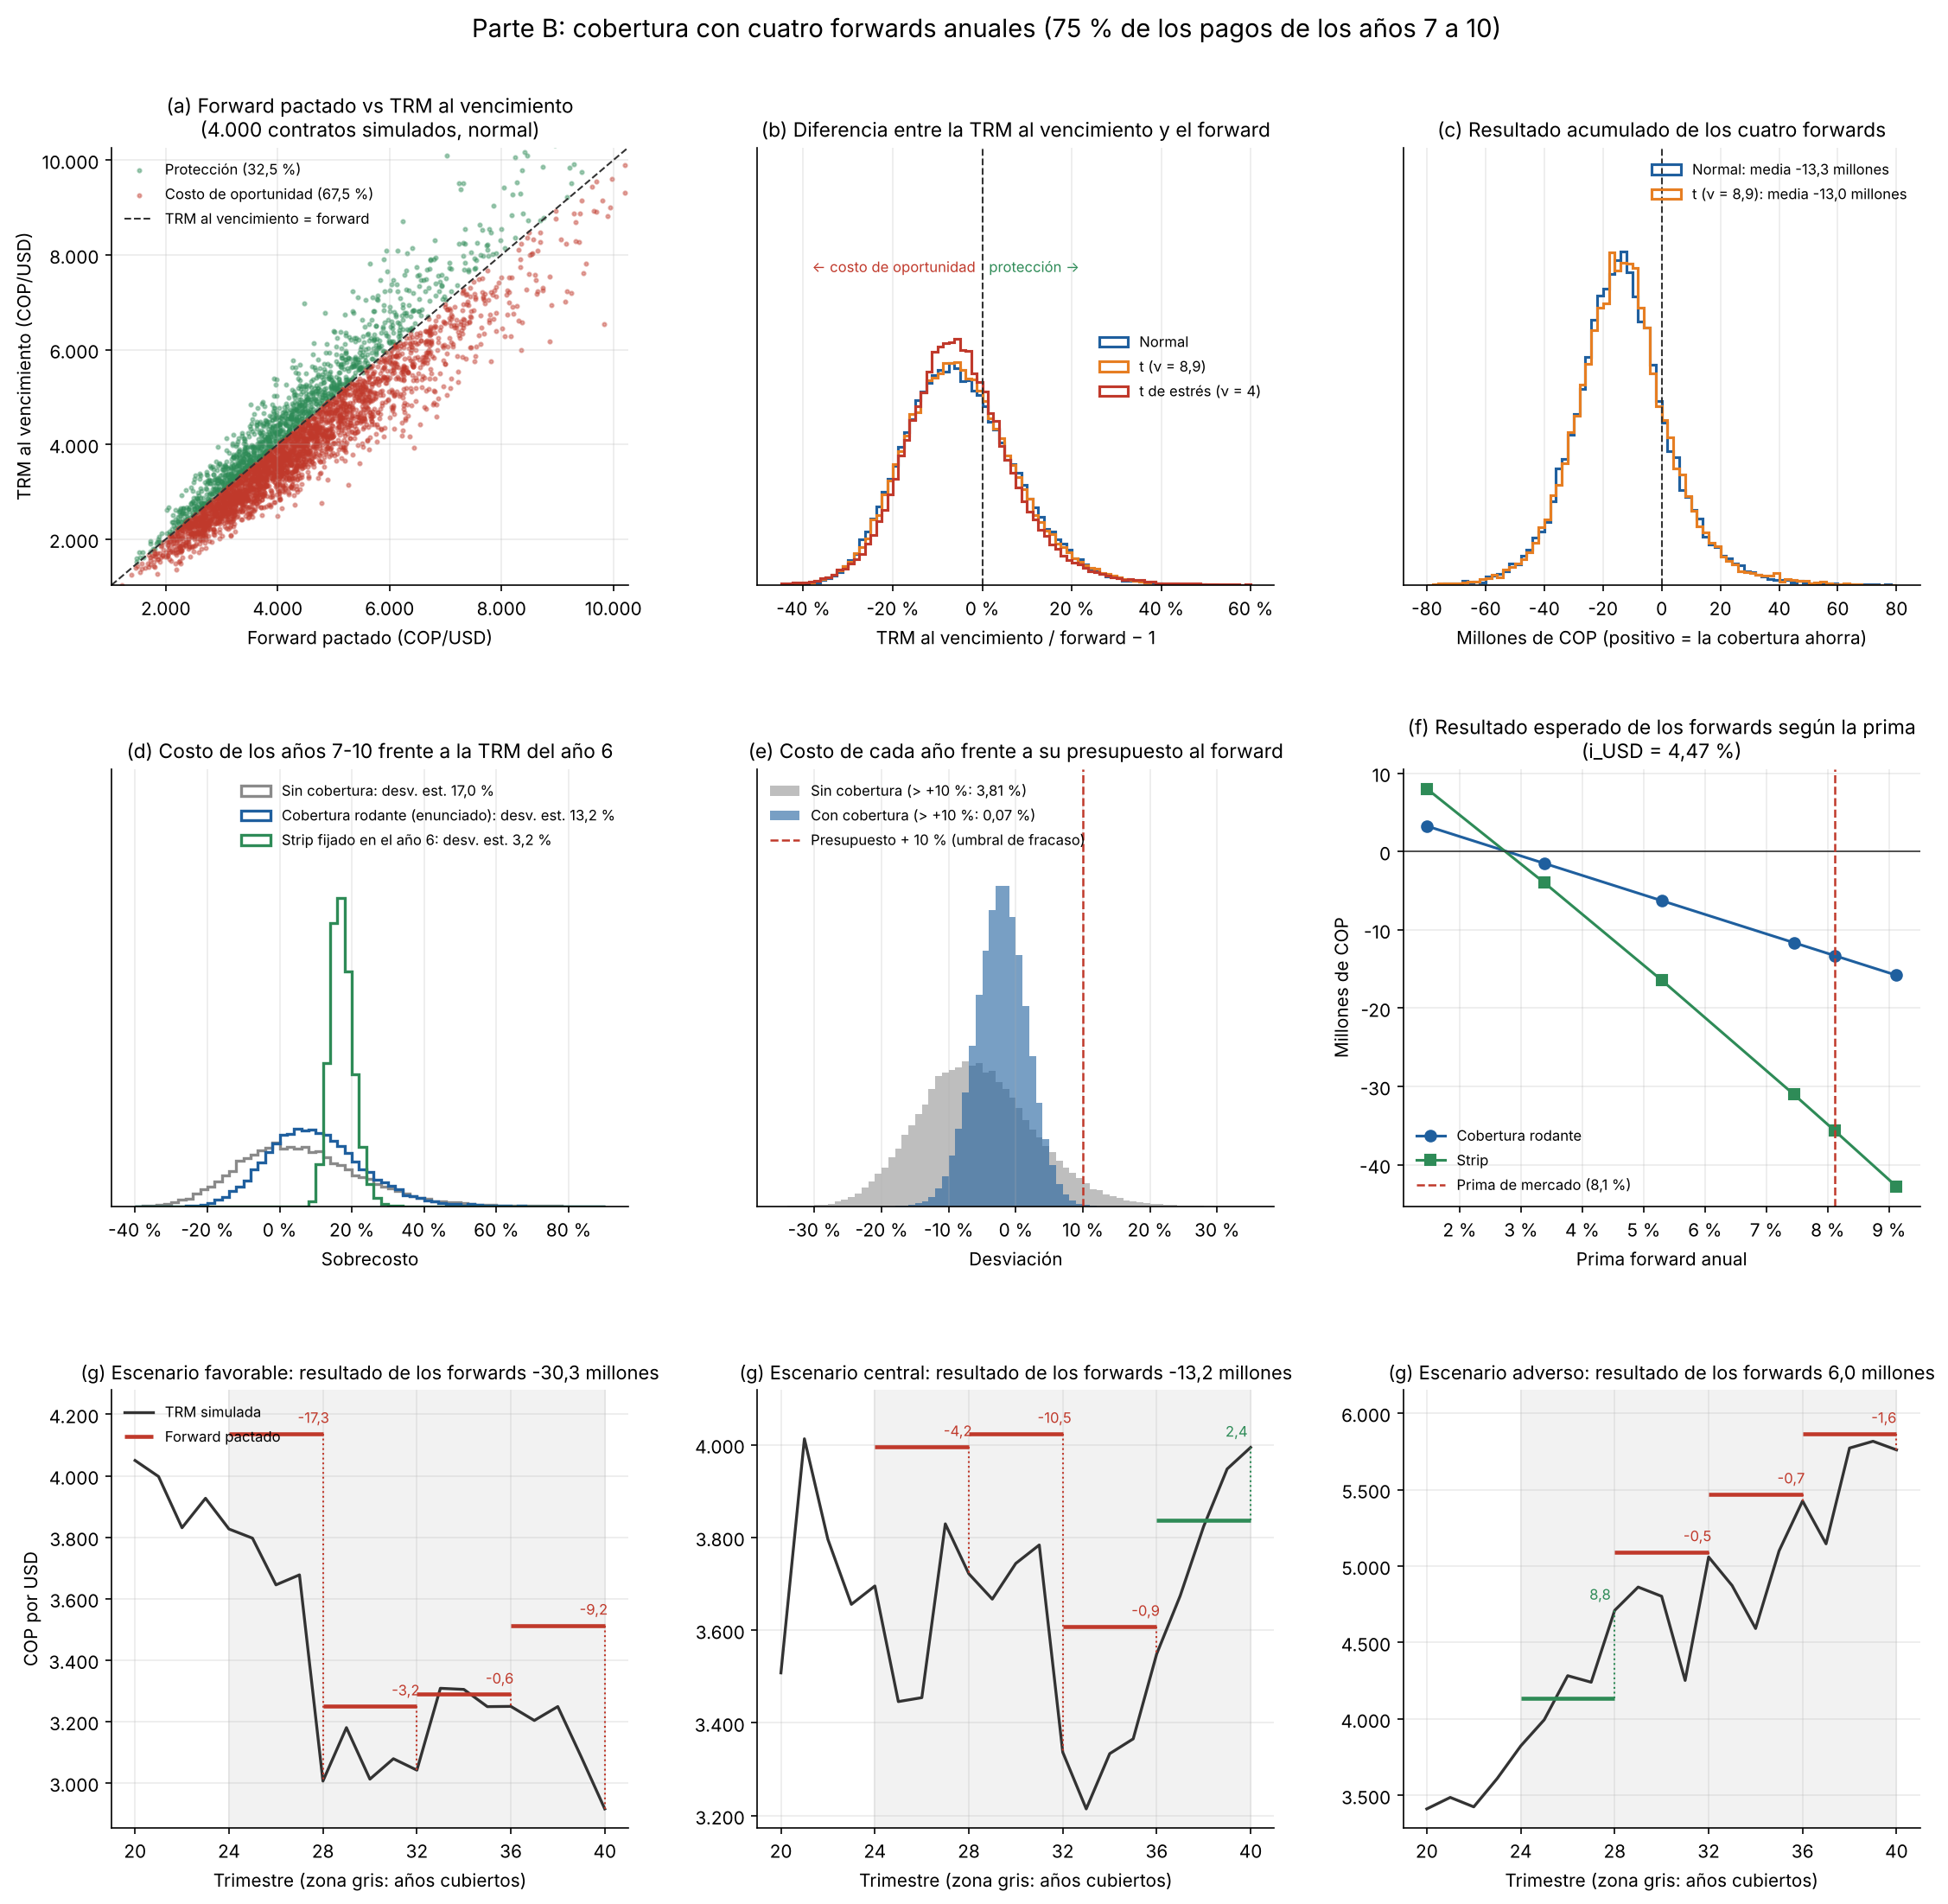

In [9]:
# Figura 2 (generada por cobertura_forward.graficas y guardada en resultados/)
display(Image("resultados/graficas_cobertura_forward.png"))

*Nota.* Fuente: elaboración propia con base en 20.000 trayectorias simuladas de la TRM.

**Tabla 17**

*Indicadores de costo y riesgo de las estrategias de cobertura*

| **Indicador (20.000 trayectorias)**          | **Normal: sin** | **Normal: rodante** | **Normal: strip** | **t: sin** | **t: rodante** | **t: strip** |
|----------------------------------------------|-----------------|---------------------|-------------------|------------|----------------|--------------|
| Costo total, media (COP millones)            | 778,3           | 791,6               | 813,9             | 778,0      | 791,1          | 813,0        |
| Costo total, desviación estándar             | 182,9           | 183,4               | 184,8             | 183,2      | 183,4          | 184,9        |
| Costo total, CVaR 95 %                       | 1.244,4         | 1.257,5             | 1.281,0           | 1.245,7    | 1.257,2        | 1.280,6      |
| Costo efectivo anual, media                  | 17,4 %          | 17,7 %              | 18,1 %            | 17,4 %     | 17,6 %         | 18,0 %       |
| Desde el año 6: sobrecosto medio años 7-10   | 6,0 %           | 10,1 %              | 17,2 %            | 6,2 %      | 10,3 %         | 17,2 %       |
| Desde el año 6: desviación estándar          | 17,0 %          | 13,2 %              | 3,2 %             | 17,4 %     | 13,5 %         | 3,3 %        |
| Desde el año 6: percentil 99                 | 52,8 %          | 46,0 %              | 25,9 %            | 54,1 %     | 47,3 %         | 26,2 %       |
| Desviación anual vs presupuesto (desv. est.) | 8,5 %           | 3,8 %               | —                 | 8,6 %      | 3,8 %          | —            |

*Nota.* «Rodante»: el forward se renueva año a año. «Strip»: variante con los cuatro precios fijados al final del año 6.

In [10]:
# Indicadores de la evaluación (millones de COP o %)
filas_B3 = ["Costo total COP – sin cobertura: media", "Costo total COP – con cobertura rodante: media",
            "Costo total COP – con strip fijado en año 6: media",
            "Costo total COP – sin cobertura: CVaR 95 %", "Costo total COP – con cobertura rodante: CVaR 95 %",
            "Resultado acumulado de los 4 forwards: media (COP)",
            "Prob. de que la cobertura rodante cueste más que no cubrir"]
t = resB["tabla"].loc[filas_B3].copy()
t.loc[filas_B3[:6]] = t.loc[filas_B3[:6]] / 1e6
t.round(3)

,Normal,t de Student (nu = 8.9),t de Student de estrés (nu = 4)
Costo total COP – sin cobertura: media,778.271,778.036,778.721
Costo total COP – con cobertura rodante: media,791.576,791.082,791.909
Costo total COP – con strip fijado en año 6: media,813.941,812.954,813.886
Costo total COP – sin cobertura: CVaR 95 %,1244.402,1245.702,1255.776
Costo total COP – con cobertura rodante: CVaR 95 %,1257.525,1257.191,1266.562
Resultado acumulado de los 4 forwards: media (COP),-13.305,-13.046,-13.188
Prob. de que la cobertura rodante cueste más que no cubrir,0.817,0.813,0.824


## Evaluación de la estrategia

### Costo y conveniencia financiera.

La cobertura no es gratis. Con la prima de mercado, los forwards cuestan en promedio COP 13,3 millones, un 1,7 % del costo total del crédito, y el costo efectivo en pesos sube de 17,4 % a 17,7 % anual. En 82 % de las trayectorias la cobertura completa termina costando más que no cubrirse. Si se mide solo por el costo esperado, la estrategia no es conveniente, pero ese no es el único factor relevante, porque su función, al final del día, es reducir el riesgo.

### Reducción de volatilidad.

La reducción depende del momento desde el que se mida. Vista desde hoy, la desviación estándar del costo total casi no cambia, porque la cobertura empieza en el año 7 y no protege los seis primeros años. Vista desde el año 6, cuando se toma la decisión, la desviación del costo de los años 7 a 10 baja de 17,0 % a 13,2 %. Dentro de cada año el efecto es mucho mayor: la desviación del costo frente a su presupuesto cae de 8,5 % a 3,8 %.

### Estabilidad presupuestal.

Una vez pactado cada forward, el costo del año es casi cierto: la probabilidad de superar el presupuesto en más de 10 % cae de 3,8 % a 0,07 %. Esta es la principal ventaja de la estrategia, pues da certeza de cuánto se terminará pagando.

### Riesgo residual.

Persisten un par de fuentes de riesgo: el 25 % que queda sin cubrir y, sobre todo, el riesgo de renovación, porque cada forward se pacta con la TRM del momento. Por eso, en el 1 % de los peores casos, el sobrecosto de los años 7 a 10 visto desde el año 6 solo baja de 52,8 % a 46,0 %. El *strip* (pactar los cuatro forwards al final del año 6) reduciría ese riesgo a 25,9 %, pero a un costo esperado casi tres veces mayor (COP 35,7 millones).

### Costo de oportunidad.

En dos de cada tres años el forward se liquida en contra. Ese pago es el precio de un seguro y no indica que la cobertura haya fallado, en esos mismos años el costo quedó dentro del presupuesto.

### Coherencia entre nominal y obligación.

El nominal de cada forward (USD 15.318) es menor que los pagos de su año (USD 20.424), y el total cubierto es menor que la obligación pendiente y que el saldo de capital. Pactar los forwards uno por año, y no todos al inicio, también reduce el riesgo de quedar sobrecubierto.

### Sensibilidad a las tasas de interés.

El resultado depende sobre todo del diferencial de tasas que exista en los años 7 a 10, que hoy no se conoce. La siguiente tabla mantiene las mismas trayectorias de la TRM y cambia solo la tasa en pesos con la que se pactan los forwards (tasa en dólares de 4,47 %):

**Tabla 18**

*Sensibilidad de la cobertura a la tasa de interés en pesos*

| **i_COP**         | **Prima forward** | **Prob. de protección** | **Resultado medio de los forwards (COP millones)** | **Prob. de que la cobertura cueste más** | **Resultado medio del strip (COP millones)** |
|-------------------|-------------------|-------------------------|----------------------------------------------------|------------------------------------------|----------------------------------------------|
| 6,00 %            | 1,5 %             | 51,2 %                  | +3,3                                               | 47,6 %                                   | +8,0                                         |
| 8,00 %            | 3,4 %             | 45,5 %                  | −1,5                                               | 58,9 %                                   | −4,0                                         |
| 10,00 %           | 5,3 %             | 40,1 %                  | −6,3                                               | 69,2 %                                   | −16,4                                        |
| 12,25 %           | 7,5 %             | 34,2 %                  | −11,6                                              | 79,1 %                                   | −31,0                                        |
| 12,95 % (mercado) | 8,1 %             | 32,5 %                  | −13,3                                              | 81,7 %                                   | −35,7                                        |
| 14,00 %           | 9,1 %             | 30,0 %                  | −15,8                                              | 85,1 %                                   | −42,8                                        |

El punto de equilibrio está en una prima de 2,5 % a 3 % anual, cercana a la depreciación esperada. Si para 2032 el diferencial de tasas entre Colombia y EE. UU. se redujera a 3 o 4 puntos, por ejemplo, porque la inflación colombiana vuelve a la meta, la cobertura costaría poco o incluso tendría un resultado esperado positivo. Si el diferencial se mantiene en los niveles actuales, seguirá siendo costosa. La reducción de riesgo, en cambio, casi no depende de las tasas.

In [11]:
# Sensibilidad a la tasa en pesos (i_USD = 4,47 %)
sens = resB["sensibilidad"]
s = sens[np.isclose(sens.i_USD, cob.I_USD)].sort_values("i_COP").copy()
s[["resultado_forwards_media", "strip_resultado_media"]] /= 1e6
s[["i_COP", "prima_forward", "prob_proteccion", "resultado_forwards_media",
   "prob_cobertura_cuesta_mas", "strip_resultado_media"]].round(4)

,i_COP,prima_forward,prob_proteccion,resultado_forwards_media,prob_cobertura_cuesta_mas,strip_resultado_media
1,0.0600,0.0146,0.5118,3.2464,0.4764,8.0125
4,0.0800,0.0338,0.4551,-1.5167,0.5888,-3.9812
7,0.1000,0.0529,0.4010,-6.2799,0.6924,-16.4351
10,0.1225,0.0745,0.3421,-11.6384,0.7911,-31.0118
13,0.1295,0.0812,0.3253,-13.3051,0.8170,-35.6707
16,0.1400,0.0912,0.3003,-15.8062,0.8506,-42.7753


### Normal frente a t de Student.

Las conclusiones no cambian con la distribución: con ν = 8,9 el CVaR del costo total sin cobertura pasa de COP 1.244 a 1.246 millones, y la cobertura conserva la misma reducción de riesgo y el mismo costo esperado.

## Conclusión de la parte B

La estrategia de cubrir el 75 % con cuatro forwards consecutivos cumple su función principal: hace casi predecible el costo de cada año a partir de su fecha de pacto y reduce entre 85 % y 90 % las pérdidas en los años de devaluación fuerte. Sin embargo, no es gratuita ni completa. Con el diferencial de tasas actual, la cobertura cuesta en promedio unos COP 13 millones y, como cada forward se renueva con la TRM del momento, no protege contra una depreciación acumulada de varios años. Por eso se concluye que la cobertura es financieramente conveniente si la empresa valora más la estabilidad presupuestal que el ahorro esperado. No lo es si el único criterio es minimizar el costo esperado, salvo que el diferencial de tasas se reduzca antes del año 7. Dos ajustes que podrían mejorar la cobertura son: empezar a cubrir antes del año 6, porque la mayor parte del riesgo se acumula en los primeros años, y combinar forwards de distintos plazos para fijar parte del precio de los años 8 a 10 desde el inicio de la cobertura.

---
### Reproducir el análisis
```bash
pip install -r requirements.txt
python simulacion_trm.py      # parte A
python cobertura_forward.py   # parte B
```
Con la semilla fija (`SEED = 42`) los resultados son idénticos a los del informe.

# Referencias

Banco de Bogotá Internacional. (s. f.). *Indicadores económicos: IBR*. Recuperado el 27 de octubre de 2026, de <https://www.bancodebogotainternacional.com/bbi/es/economicindicator>

Banco de la República. (s. f.). *Estadísticas económicas: TRM y tasa de política monetaria*. Recuperado el 27 de octubre de 2026, de <https://totoro.banrep.gov.co/estadisticas-economicas/>

Bloomberg Línea. (2026). *Déficit externo de Colombia se amplía a US\$5.981 millones en el primer semestre de 2026*. <https://www.bloomberglinea.com/latinoamerica/colombia/deficit-externo-de-colombia-se-amplia-a-us5981-millones-en-el-primer-semestre-de-2026/>

Board of Governors of the Federal Reserve System. (2026, 26 de octubre). *Selected interest rates (daily): H.15*. <https://www.federalreserve.gov/releases/h15/>

Cbonds. (s. f.-a). *Curva forward USD/COP por plazos*. Recuperado el 27 de octubre de 2026, de <https://cbonds.com.tr/indexes/215883/>

Cbonds. (s. f.-b). *USD/COP 1Y FX forward rate (mid)*. Recuperado el 27 de octubre de 2026, de <https://cbonds.com/indexes/215895/>

Chase. (2026). *Federal Reserve raises rates, officials signal one more hike in 2026*. <https://www.chase.com/personal/investments/learning-and-insights/article/federal-reserve-raises-rates-officials-signal-one-more-hike-in-2026>

Coleman Report. (2026). *SBA hot topic Tuesday: Grocery, manufacturing and rural businesses get new FY 2027 fee relief*. <https://colemanreport.com/sba-hot-topic-tuesday-grocery-manufacturing-and-rural-businesses-get-new-fy-2027-fee-relief/>

Crowdfunded Wealth. (2026). *SBA 504 loan rates 2026*. <https://www.crowdfundedwealth.com/articles/sba-504-loan-rates-2026>

Diario del Huila. (2026). *Proyección del dólar en Colombia 2026*. <https://diariodelhuila.com/proyeccion-dolar-colombia-2026/>

El Colombiano. (2026). *Colombia baja calificación de riesgo de S&P por déficit fiscal*. <https://www.elcolombiano.com/negocios/colombia-baja-calificacion-riesgo-sp-deficit-fiscal-IG35331339>

El Espectador. (2026). *S&P rebaja la calificación de Colombia a BB−: las razones detrás de la decisión*. <https://www.elespectador.com/economia/sp-rebaja-la-calificacion-de-colombia-a-bb-las-razones-detras-de-la-decision/>

Federal Reserve Bank of St. Louis. (s. f.-a). *Secured Overnight Financing Rate (SOFR)* \[Base de datos FRED\]. Recuperado el 27 de octubre de 2026, de <https://fred.stlouisfed.org/series/SOFR>

Federal Reserve Bank of St. Louis. (s. f.-b). *Tasa de cambio de Colombia frente al dólar, fin de periodo, trimestral (COLCCUSSP02STQ)* \[Base de datos FRED\]. Recuperado el 27 de octubre de 2026, de <https://fred.stlouisfed.org/series/COLCCUSSP02STQ>

Forex Fundamentals. (2026, 14 de octubre). *US CPI: septiembre de 2026* \[Calendario económico\]. <https://forexfundamentals.com/economic-calendar/us-cpi/2026-10-14>

Global66. (2026, 16 de octubre). *Dólar hoy en Colombia: análisis semanal, 16 de octubre de 2026*. <https://www.global66.com/blog/dolar-hoy-colombia-analisis-semanal-16-octubre-2026/>

Infobae. (2026a, 18 de octubre). *Créditos y costo de vida se encarecerían en Colombia ante el desajuste de dinero que le dejó Gustavo Petro al país*. <https://www.infobae.com/colombia/2026/10/18/creditos-y-costo-de-vida-se-encarecerian-en-colombia-ante-el-desajuste-de-dinero-que-le-dejo-gustavo-petro-al-pais-es-dispararnos-en-el-pie/>

Infobae. (2026b, 26 de octubre). *Dólar hoy en Colombia: cotización de cierre del 26 de octubre*. <https://www.infobae.com/colombia/2026/10/26/dolar-hoy-en-colombia-cotizacion-de-cierre-del-26-de-octubre/>

La República. (s. f.). *TES*. Recuperado el 27 de octubre de 2026, de <https://www.larepublica.co/tes>

La República. (2026a). *El efecto electoral llevó el riesgo país a mínimos no registrados desde 2021*. <https://www.larepublica.co/economia/el-efecto-electoral-llevo-el-riesgo-pais-a-minimos-no-registrados-desde-2021-4438721>

La República. (2026b). *Las tasas de los bonos TES de corto plazo alcanzaron máximos de más de dos décadas*. <https://www.larepublica.co/economia/las-tasas-de-los-bonos-tes-de-corto-plazo-alcanzaron-maximos-de-mas-de-dos-decadas-4394066>

NAGGL. (2026). *Procedural notice revising SOP 50 10 8 for new citizenship and residency requirements*. <https://www.naggl.org/procedural-notice-revising-sop-50-10-8-for-new-citizenship-and-residency-requirements/>

NerdWallet. (s. f.-a). *SBA 504 loans*. Recuperado el 27 de octubre de 2026, de <https://www.nerdwallet.com/business/loans/learn/sba-504-loans>

NerdWallet. (s. f.-b). *SBA 7(a) loan*. Recuperado el 27 de octubre de 2026, de <https://www.nerdwallet.com/business/loans/learn/sba-7a-loan>

NerdWallet. (s. f.-c). *SBA lenders*. Recuperado el 27 de octubre de 2026, de <https://www.nerdwallet.com/business/loans/learn/sba-lenders>

NerdWallet. (s. f.-d). *SBA loan rates*. Recuperado el 27 de octubre de 2026, de <https://www.nerdwallet.com/article/small-business/sba-loan-rates>

Portafolio. (2025). *Calificación crediticia de Colombia baja por déficit fiscal y deuda creciente: análisis de S&P y Moody's*. <https://www.portafolio.co/economia/crecimiento/calificacion-crediticia-de-colombia-baja-por-deficit-fiscal-y-deuda-creciente-analisis-de-s-p-y-moody-s-634057>

Portafolio. (2026a, 24 de octubre). *Dólar en Colombia: el alza esperada para el cierre de 2026 y por qué podría subir a \$3.600 en 2027, según Credicorp*. <https://www.portafolio.co/economia/finanzas/dolar-en-colombia-el-alza-esperada-para-el-cierre-de-2026-y-por-que-podria-subir-a-3-600-en-2027-segun-credicorp-505043>

Portafolio. (2026b). *El Banco de la República aumenta la tasa de interés en 25 puntos básicos y queda en 12,25 %*. <https://www.portafolio.co/economia/finanzas/el-banco-de-la-republica-aumenta-la-tasa-de-interes-en-25-puntos-basicos-y-queda-en-12-503597>

Portafolio. (2026c). *Inflación en Colombia sigue subiendo: se ubicó en 6,29 % en septiembre*. <https://www.portafolio.co/economia/finanzas/inflacion-en-colombia-sigue-subiendo-se-ubico-en-6-29-en-septiembre-de-504077>

Portafolio. (2026d, 23 de octubre). *Precio del dólar hoy en Colombia: así cotiza la divisa al cierre de la semana*. <https://www.portafolio.co/economia/finanzas/precio-del-dolar-hoy-en-colombia-asi-cotiza-la-divisa-al-cierre-de-la-semana-504976>

Portafolio. (2026e). *Una inflación de 6,87 % elevaría las tasas del Banco de la República a 12,50 % al cierre de 2026, advierte estudio*. <https://www.portafolio.co/economia/gobierno/una-inflacion-de-6-87-elevaria-las-tasas-del-banco-de-la-republica-a-12-50-al-cierre-de-2026-advierte-estudio-504862>

Pound Sterling Live. (s. f.-a). *Historial USD/COP 2024*. Recuperado el 27 de octubre de 2026, de <https://www.poundsterlinglive.com/history/USD-COP-2024>

Pound Sterling Live. (s. f.-b). *Historial USD/COP 2025*. Recuperado el 27 de octubre de 2026, de <https://www.poundsterlinglive.com/history/USD-COP-2025>

PrimeRates. (2026). *Prime rate rises to 7 percent: Fed's first hike since July 2023*. <https://primerates.com/prime-rate-rises-7-percent-fed-first-hike-since-july-2023/>

Rigzone. (2026, 8 de octubre). *EIA boosts oil price forecast by 5% in 2026, 10% in 2027*. <https://www.rigzone.com/news/eia_boosts_oil_price_forecast_by_5_in_2026_10_in_2027-08-oct-2026-184805-article/>

Superintendencia Financiera de Colombia. (s. f.). *Histórico TRM para estados financieros*. Recuperado el 27 de octubre de 2026, de <https://www.superfinanciera.gov.co/publicaciones/9332/informes-y-cifrascifrasestablecimientos-de-creditoinformacion-periodicamensualtasas-de-referencia-mensualhistorico-trm-para-estados-financieros-9332/>

U.S. Bank. (s. f.). *SBA loans*. Recuperado el 27 de octubre de 2026, de <https://www.usbank.com/business-banking/business-lending/sba-loans.html>

U.S. Bank. (2026a). *U.S. Bank boosts SBA lending to a record \$943 million in 7(a) loans*. <https://www.usbank.com/about-us-bank/news-and-stories/article-library/us-bank-boosts-sba-lending-to-a-record-943-million-in-7a-loans.html>

U.S. Bank. (2026b, 16 de septiembre). *U.S. Bank increases prime lending rate to 7.00 percent* \[Comunicado de prensa\]. <https://s203.q4cdn.com/711684571/files/doc_news/U-S--Bank-Increases-Prime-Lending-Rate-to-7-00-Percent-2026.pdf>

U.S. Small Business Administration. (s. f.). *Términos, condiciones y elegibilidad*. Recuperado el 27 de octubre de 2026, de <https://www.sba.gov/es/node/8664>

University of Wisconsin–Stevens Point. (2026). *7(a) and 504 loan programs* \[Diapositivas\]. <https://www.uwsp.edu/continuing-education-and-outreach/wp-content/uploads/sites/68/2026/05/7-504-Loan-Program-Slides.pdf>

Valora Analitik. (2026, 11 de octubre). *Dólar en Colombia llegaría a \$4.000*. Yahoo Noticias. <https://es-us.noticias.yahoo.com/d%C3%B3lar-colombia-llegar%C3%ADa-4-000-170000304.html>

ValutaFX. (s. f.). *Historial COP/USD 2026*. Recuperado el 27 de octubre de 2026, de <https://www.valutafx.com/history/cop-usd-2026>

Wilkinson PC. (s. f.). *Dólar hoy: TRM certificada por la Superintendencia Financiera*. Recuperado el 27 de octubre de 2026, de <https://dolar.wilkinsonpc.com.co/>

XTB. (2025). *Fitch rebaja la calificación de Colombia a BB y alerta por déficits fiscales persistentes*. <https://www.xtb.com/lat/analisis-y-noticias/analisis-de-mercado/fitch-rebaja-la-calificacion-de-colombia-a-bb-y-alerta-por-deficits-fiscales-persistentes>